# Dubai Property Price Estimator: analysis and model

**Question:** given an apartment or villa in Dubai (area, type, bedrooms, size,
off-plan or ready), what is a fair sale price?

**Data:** official sales transactions published by the **Dubai Land Department (DLD)**
on its [Real Estate Data](https://dubailand.gov.ae/en/open-data/real-estate-data/) page,
1 January to 15 October 2026. Download the "Transactions" CSV into `data/`.

**Steps**
1. Clean the data (remove gifts, bulk developer registrations, impossible sizes and prices)
2. Explore the market with charts
3. Build a simple baseline, then a gradient-boosting model
4. Test honestly: train on January–August, test on September–October
5. Export the model and market statistics for the web dashboard

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data"
DOCS = ROOT / "docs"
WEB_DATA = ROOT / "web" / "data"
DOCS.mkdir(exist_ok=True)
WEB_DATA.mkdir(parents=True, exist_ok=True)

SQM_TO_SQFT = 10.7639
COLORS = {"Flat": "#2b59ff", "Villa": "#d63c8f"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

csv_files = sorted(DATA.glob("transactions*.csv"))
raw = pd.concat([pd.read_csv(f, low_memory=False) for f in csv_files]).drop_duplicates("TRANSACTION_NUMBER")
print(f"{len(raw):,} transactions loaded from {len(csv_files)} file(s)")

129,748 transactions loaded from 1 file(s)


## 1. Cleaning

Real data is messy. Every rule below is written down so the analysis can be repeated:

| Rule | Why |
|---|---|
| Keep **flats** and **villas** used as homes | offices, shops, land and hotel rooms are priced differently |
| Keep real **sale procedures** only | lease-to-own and bulk developer registrations are not market sales |
| Bedrooms must be known | the model needs it (Studio = 0) |
| Flats 200–6,000 sq ft, villas 700–20,000 sq ft | removes data-entry errors |
| Price ≥ AED 100,000 | removes symbolic transfers |
| Price per sq ft between the 0.5th and 99.5th percentile (per type) | removes extreme outliers |

In [2]:
SALE_PROCEDURES = {"Sell - Pre registration", "Sale", "Delayed Sell", "Sale On Payment Plan"}
SMALL_WORDS = {"of", "and", "the"}
ROMAN = {"I", "II", "III", "IV", "V", "VI"}
ACRONYMS = {"DMCC", "JLT", "JVC", "JVT", "DIFC", "DIP", "IMPZ", "MBR", "EZ"}


def tidy_area(name: str) -> str:
    """DLD mixes 'BUSINESS BAY' and 'Business Bay'; make every area name Title Case."""
    words = re.split(r"(\s+|-)", str(name).strip())
    out = []
    for w in words:
        if w.upper() in ROMAN or w.upper() in ACRONYMS or any(ch.isdigit() for ch in w) and w.isalnum() and not w.isdigit():
            out.append(w.upper())
        elif w.lower() in SMALL_WORDS and out:
            out.append(w.lower())
        else:
            out.append(w[:1].upper() + w[1:].lower())
    return "".join(out)


def bedrooms(value):
    if value == "Studio":
        return 0
    m = re.match(r"(\d+)\s*B/R", str(value))
    return int(m.group(1)) if m else np.nan


df = raw.copy()
df["type"] = np.select(
    [(df.PROP_TYPE_EN == "Unit") & (df.PROP_SB_TYPE_EN == "Flat"),
     (df.PROP_TYPE_EN == "Building") & (df.PROP_SB_TYPE_EN == "Villa")],
    ["Flat", "Villa"], default="other")
steps = [("All sales transactions", len(df))]

df = df[(df.type != "other") & (df.USAGE_EN == "Residential")]
steps.append(("Residential flats and villas", len(df)))
df = df[df.PROCEDURE_EN.isin(SALE_PROCEDURES)]
steps.append(("Real sale procedures", len(df)))

df["date"] = pd.to_datetime(df.INSTANCE_DATE)
df["month"] = df.date.dt.month
df["area"] = df.AREA_EN.map(tidy_area)
df["bedrooms"] = df.ROOMS_EN.map(bedrooms)
df["sqft"] = df.ACTUAL_AREA * SQM_TO_SQFT
df["price"] = df.TRANS_VALUE
df["offplan"] = (df.IS_OFFPLAN_EN == "Off-Plan").astype(int)
df = df.dropna(subset=["bedrooms", "sqft", "price"])
steps.append(("Bedrooms known", len(df)))

size_ok = ((df.type == "Flat") & df.sqft.between(200, 6000)) | ((df.type == "Villa") & df.sqft.between(700, 20000))
df = df[size_ok & (df.price >= 100_000)]
steps.append(("Realistic size and price", len(df)))

df["ppsf"] = df.price / df.sqft
lo = df.groupby("type").ppsf.transform(lambda s: s.quantile(0.005))
hi = df.groupby("type").ppsf.transform(lambda s: s.quantile(0.995))
df = df[df.ppsf.between(lo, hi)].reset_index(drop=True)
steps.append(("Without extreme price per sq ft", len(df)))

for label, n in steps:
    print(f"{label:<35} {n:>9,}")
print(f"\nClean dataset: {len(df):,} sales · {df.area.nunique()} areas · {df.date.min():%d %b} to {df.date.max():%d %b %Y}")

All sales transactions                129,748
Residential flats and villas          111,030
Real sale procedures                  107,807
Bedrooms known                        107,778
Realistic size and price              107,058
Without extreme price per sq ft       105,986

Clean dataset: 105,986 sales · 143 areas · 01 Jan to 15 Oct 2026


## 2. The market at a glance

In [3]:
summary = df.groupby("type").agg(sales=("price", "size"), median_price=("price", "median"),
                                 median_sqft=("sqft", "median"), median_ppsf=("ppsf", "median"),
                                 offplan_share=("offplan", "mean"))
summary.style.format({"median_price": "AED {:,.0f}", "median_sqft": "{:,.0f}", "median_ppsf": "AED {:,.0f}",
                      "offplan_share": "{:.0%}", "sales": "{:,}"})

,sales,median_price,median_sqft,median_ppsf,offplan_share
type,,,,,
Flat,"96,970","AED 1,230,068",765,"AED 1,722",76%
Villa,"9,016","AED 3,416,640","1,896","AED 1,772",72%


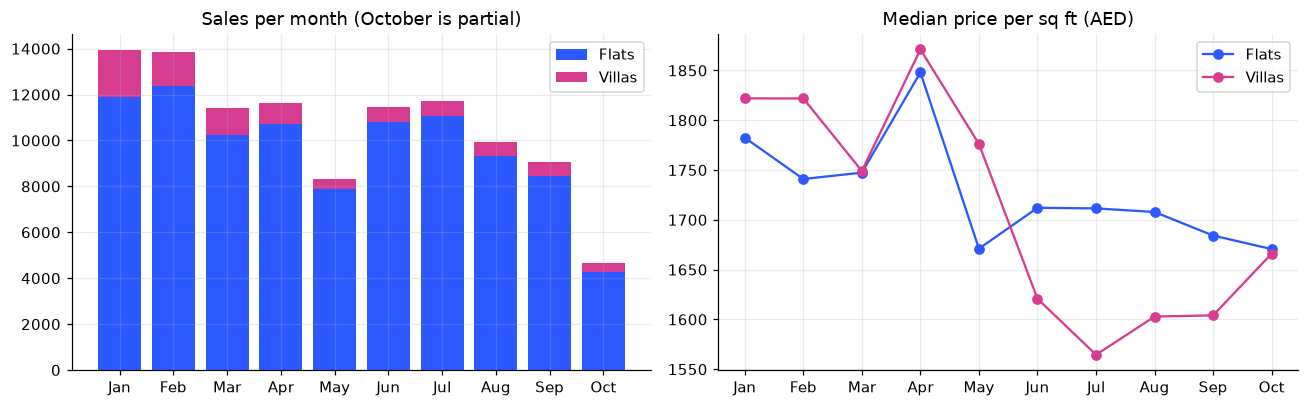

In [4]:
monthly = df.groupby(["month", "type"]).agg(sales=("price", "size"), ppsf=("ppsf", "median")).unstack("type")
months = [pd.Timestamp(2026, m, 1).strftime("%b") for m in monthly.index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.bar(months, monthly["sales"]["Flat"], color=COLORS["Flat"], label="Flats")
a1.bar(months, monthly["sales"]["Villa"], bottom=monthly["sales"]["Flat"], color=COLORS["Villa"], label="Villas")
a1.set_title("Sales per month (October is partial)"); a1.legend()
for t in ["Flat", "Villa"]:
    a2.plot(months, monthly["ppsf"][t], marker="o", color=COLORS[t], label=f"{t}s")
a2.set_title("Median price per sq ft (AED)"); a2.legend()
plt.tight_layout(); plt.savefig(DOCS / "monthly.png", bbox_inches="tight"); plt.show()

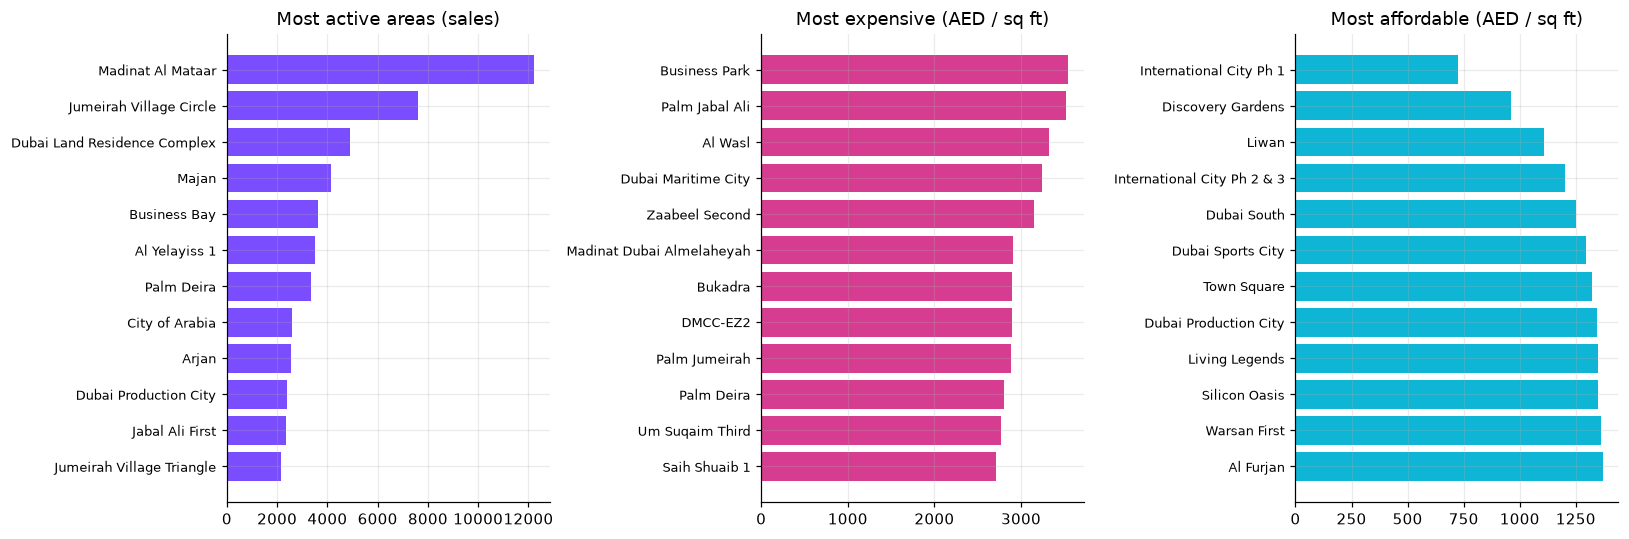

In [5]:
area_stats = df.groupby("area").agg(sales=("price", "size"), median_ppsf=("ppsf", "median"))
busy = area_stats[area_stats.sales >= 300]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
top = area_stats.sales.nlargest(12).sort_values()
axes[0].barh(top.index, top.values, color="#7a4dff"); axes[0].set_title("Most active areas (sales)")
exp = busy.median_ppsf.nlargest(12).sort_values()
axes[1].barh(exp.index, exp.values, color="#d63c8f"); axes[1].set_title("Most expensive (AED / sq ft)")
cheap = busy.median_ppsf.nsmallest(12).sort_values(ascending=False)
axes[2].barh(cheap.index, cheap.values, color="#0fb5d4"); axes[2].set_title("Most affordable (AED / sq ft)")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); plt.savefig(DOCS / "areas.png", bbox_inches="tight"); plt.show()

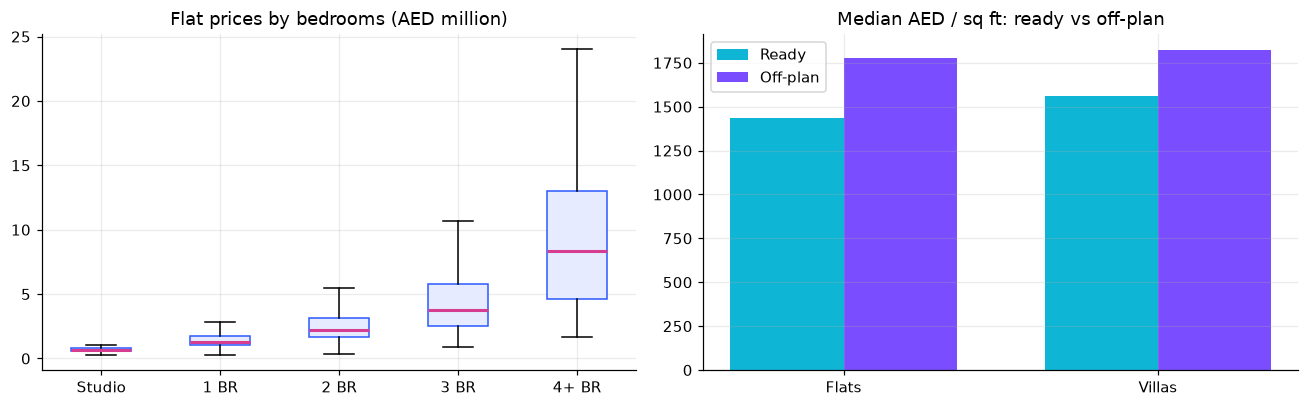

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
flats = df[df.type == "Flat"]
labels = ["Studio", "1 BR", "2 BR", "3 BR", "4+ BR"]
groups = [flats[flats.bedrooms == b].price / 1e6 for b in range(4)] + [flats[flats.bedrooms >= 4].price / 1e6]
a1.boxplot(groups, tick_labels=labels, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#e6ebff", color="#2b59ff"), medianprops=dict(color="#d63c8f", linewidth=2))
a1.set_title("Flat prices by bedrooms (AED million)")
op = df.groupby(["type", "offplan"]).ppsf.median().unstack()
x = np.arange(2)
a2.bar(x - 0.18, op[0], 0.36, label="Ready", color="#0fb5d4")
a2.bar(x + 0.18, op[1], 0.36, label="Off-plan", color="#7a4dff")
a2.set_xticks(x, ["Flats", "Villas"]); a2.set_title("Median AED / sq ft: ready vs off-plan"); a2.legend()
plt.tight_layout(); plt.savefig(DOCS / "bedrooms_offplan.png", bbox_inches="tight"); plt.show()

## 3. Features, and an honest test

**Time-based split:** the model learns from **January–August** and is tested on
**September–October**. A random split would let the model "peek" at sales from the same
weeks it is tested on; a time split mimics real use, predicting sales that haven't
happened yet.

**Area encoding:** there are 100+ areas. Instead of 100+ yes/no columns, each area becomes
one number: its typical (log) price per sq ft in the *training* months, pulled towards the
city-wide average when an area has few sales (so 3 sales don't dominate). This is called
**smoothed target encoding**.

In [7]:
FEATURES = ["area_value", "area_type_value", "area_sales_log", "is_villa", "offplan", "bedrooms", "log_sqft"]
SMOOTH = 30


def area_encoding(train: pd.DataFrame):
    """Smoothed mean log price-per-sqft, per area and per (area, type)."""
    y = np.log(train.ppsf)
    global_mean = y.mean()
    g = train.assign(y=y).groupby("area").y.agg(["mean", "count"])
    area_value = (g["mean"] * g["count"] + global_mean * SMOOTH) / (g["count"] + SMOOTH)
    type_mean = train.assign(y=y).groupby("type").y.mean()
    gt = train.assign(y=y).groupby(["area", "type"]).y.agg(["mean", "count"])
    prior = [type_mean[t] for t in gt.index.get_level_values("type")]
    area_type_value = (gt["mean"] * gt["count"] + np.array(prior) * SMOOTH) / (gt["count"] + SMOOTH)
    return {"global": float(global_mean), "type_mean": type_mean.to_dict(),
            "area": area_value.to_dict(), "area_type": area_type_value.to_dict(),
            "sales": g["count"].to_dict()}


def make_features(d: pd.DataFrame, enc: dict) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    X["area_value"] = d.area.map(enc["area"]).fillna(enc["global"])
    keys = list(zip(d.area, d.type))
    X["area_type_value"] = [enc["area_type"].get(k, enc["type_mean"][k[1]]) for k in keys]
    X["area_sales_log"] = np.log1p(d.area.map(enc["sales"]).fillna(0))
    X["is_villa"] = (d.type == "Villa").astype(int)
    X["offplan"] = d.offplan
    X["bedrooms"] = d.bedrooms
    X["log_sqft"] = np.log(d.sqft)

    return X[FEATURES]


train, test = df[df.month <= 8], df[df.month >= 9]
enc = area_encoding(train)
X_train, X_test = make_features(train, enc), make_features(test, enc)
y_train = np.log(train.ppsf)
print(f"Train: {len(train):,} sales (Jan–Aug) · Test: {len(test):,} sales (Sep–Oct)")


def report(name, pred_price, actual):
    pct_err = np.abs(pred_price - actual) / actual
    return {"model": name,
            "median % error": f"{np.median(pct_err) * 100:.1f}%",
            "within 10%": f"{(pct_err <= 0.10).mean() * 100:.0f}%",
            "within 20%": f"{(pct_err <= 0.20).mean() * 100:.0f}%",
            "R² (log price)": round(1 - np.sum((np.log(pred_price) - np.log(actual)) ** 2)
                                    / np.sum((np.log(actual) - np.log(actual).mean()) ** 2), 3)}

Train: 92,265 sales (Jan–Aug) · Test: 13,721 sales (Sep–Oct)


### Baseline first
Before any machine learning: *"area's typical price per sq ft × size"*. A model is only
useful if it clearly beats this.

In [8]:
base_ppsf = train.groupby(["area", "type"]).ppsf.median()
type_ppsf = train.groupby("type").ppsf.median()
base_pred = np.array([base_ppsf.get((a, t), type_ppsf[t]) for a, t in zip(test.area, test.type)]) * test.sqft
results = [report("Baseline: area median × size", base_pred, test.price)]
pd.DataFrame(results)

,model,median % error,within 10%,within 20%,R² (log price)
0,Baseline: area median × size,11.1%,46%,71%,0.883


### Gradient boosting
**HistGradientBoostingRegressor** builds hundreds of small decision trees, each one fixing
the mistakes of the trees before it. It predicts the log of the price per sq ft; the price
is then `exp(prediction) × size`.

In [9]:
model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=31,
                                      min_samples_leaf=40, l2_regularization=1.0, random_state=42)
model.fit(X_train, y_train)
pred_price = np.exp(model.predict(X_test)) * test.sqft
results.append(report("Gradient boosting", pred_price, test.price))
results_df = pd.DataFrame(results)
results_df

,model,median % error,within 10%,within 20%,R² (log price)
0,Baseline: area median × size,11.1%,46%,71%,0.883
1,Gradient boosting,8.3%,57%,83%,0.934


In [10]:
by_type = []
for t in ["Flat", "Villa"]:
    m = (test.type == t).values
    r = report(t + "s", pred_price[m], test.price.values[m]); r["sales"] = int(m.sum())
    by_type.append(r)
pd.DataFrame(by_type)

,model,median % error,within 10%,within 20%,R² (log price),sales
0,Flats,8.3%,56%,83%,0.922,12714
1,Villas,8.1%,59%,85%,0.867,1007


### Which features matter?
**Permutation importance:** shuffle one feature at a time and see how much worse the
predictions get. A big drop means the model relies on that feature.

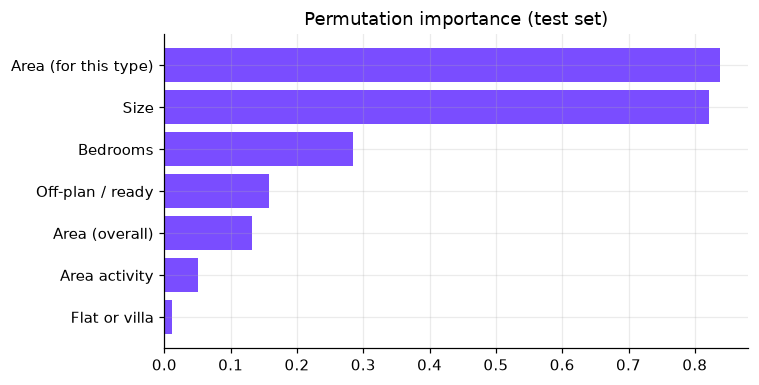

In [11]:
imp = permutation_importance(model, X_test, np.log(test.ppsf), n_repeats=5, random_state=0, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
nice = {"area_value": "Area (overall)", "area_type_value": "Area (for this type)", "area_sales_log": "Area activity",
        "is_villa": "Flat or villa", "offplan": "Off-plan / ready", "bedrooms": "Bedrooms",
        "log_sqft": "Size"}
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([nice[i] for i in importance.index], importance.values, color="#7a4dff")
ax.set_title("Permutation importance (test set)")
plt.tight_layout(); plt.savefig(DOCS / "importance.png", bbox_inches="tight"); plt.show()

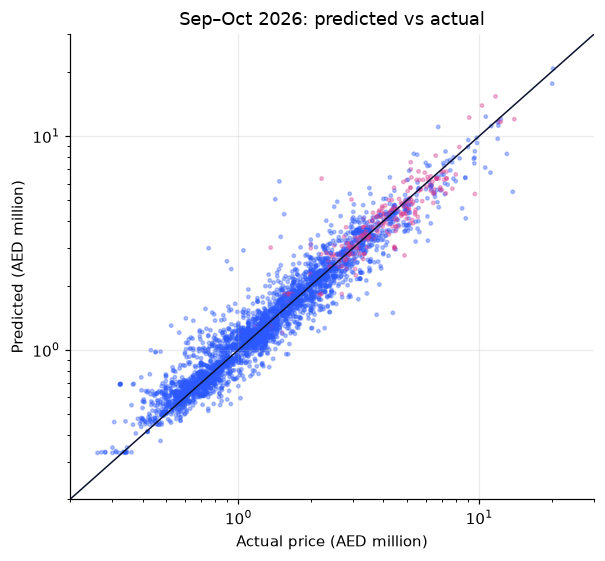

In [12]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
sample = np.random.default_rng(0).choice(len(test), 4000, replace=False)
ax.scatter(test.price.values[sample] / 1e6, pred_price.values[sample] / 1e6, s=5, alpha=0.35,
           c=["#d63c8f" if t == "Villa" else "#2b59ff" for t in test.type.values[sample]])
lim = [0.2, 30]
ax.plot(lim, lim, color="#0d1230", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual price (AED million)"); ax.set_ylabel("Predicted (AED million)")
ax.set_title("Sep–Oct 2026: predicted vs actual")
plt.tight_layout(); plt.savefig(DOCS / "predicted_vs_actual.png", bbox_inches="tight"); plt.show()

## 4. Final model and export

After the honest test, the final model is retrained on **all** months so the website uses
the most recent prices. The test-set errors are used to show a realistic **price range**
(the middle 80% of errors) next to every estimate.

The web app runs the trees itself in JavaScript, so we export every tree as plain JSON
and check that a simple tree-walking function gives exactly the same predictions as
scikit-learn.

In [13]:
log_ratio = np.log(test.price.values / pred_price.values)
band = {"low": float(np.exp(np.quantile(log_ratio, 0.10))), "high": float(np.exp(np.quantile(log_ratio, 0.90)))}

enc_all = area_encoding(df)
final = HistGradientBoostingRegressor(**model.get_params()).fit(make_features(df, enc_all), np.log(df.ppsf))


def export_trees(m):
    trees = []
    for (predictor,) in m._predictors:
        n = predictor.nodes
        trees.append({"f": n["feature_idx"].tolist(), "t": [float(v) for v in n["num_threshold"]],
                      "l": n["left"].tolist(), "r": n["right"].tolist(),
                      "v": [float(v) for v in n["value"]], "leaf": n["is_leaf"].astype(int).tolist()})
    return {"features": FEATURES, "baseline": float(np.ravel(m._baseline_prediction)[0]), "trees": trees}


def walk(exported, row):
    total = exported["baseline"]
    for tr in exported["trees"]:
        i = 0
        while not tr["leaf"][i]:
            i = tr["l"][i] if row[tr["f"][i]] <= tr["t"][i] else tr["r"][i]
        total += tr["v"][i]
    return total


exported = export_trees(final)
check = make_features(df.sample(300, random_state=1), enc_all)
diff = np.abs(np.array([walk(exported, r) for r in check.values]) - final.predict(check)).max()
print(f"{len(exported['trees'])} trees exported · max difference vs scikit-learn: {diff:.2e}")

400 trees exported · max difference vs scikit-learn: 0.00e+00


In [14]:
areas_out = []
for area, g in df.groupby("area"):
    if len(g) < 25:
        continue
    entry = {"name": area, "sales": int(len(g)), "value": round(enc_all["area"][area], 5),
             "sales_log": round(float(np.log1p(enc_all["sales"][area])), 5), "types": {}}
    for t, gt in g.groupby("type"):
        entry["types"][t] = {"value": round(enc_all["area_type"][(area, t)], 5), "sales": int(len(gt)),
                             "median_ppsf": round(float(gt.ppsf.median())), "median_price": round(float(gt.price.median()))}
    areas_out.append(entry)

dashboard = {
    "period": f"{df.date.min():%d %b} – {df.date.max():%d %b %Y}",
    "updated": f"{df.date.max():%Y-%m-%d}",
    "total_sales": int(len(df)), "total_value": float(df.price.sum()),
    "median_ppsf": round(float(df.ppsf.median())), "offplan_share": round(float(df.offplan.mean()), 3),
    "by_type": {t: {"sales": int(r.sales), "median_price": round(float(r.median_price)), "median_ppsf": round(float(r.median_ppsf))}
                for t, r in summary.iterrows()},
    "monthly": [{"month": pd.Timestamp(2026, int(m), 1).strftime("%b"),
                 "flats": int(monthly["sales"]["Flat"][m]), "villas": int(monthly["sales"]["Villa"][m]),
                 "flat_ppsf": round(float(monthly["ppsf"]["Flat"][m])), "villa_ppsf": round(float(monthly["ppsf"]["Villa"][m]))}
                for m in monthly.index],
    "top_areas": [{"area": a, "sales": int(n)} for a, n in area_stats.sales.nlargest(10).items()],
    "expensive": [{"area": a, "ppsf": round(float(v))} for a, v in busy.median_ppsf.nlargest(8).items()],
    "affordable": [{"area": a, "ppsf": round(float(v))} for a, v in busy.median_ppsf.nsmallest(8).items()],
    "bedrooms": [{"label": l, "median_price": round(float(g.median() * 1e6))} for l, g in zip(labels, groups)],
}
metrics = {"test_period": "Sep–Oct 2026", "train_period": "Jan–Aug 2026", "train_sales": int(len(train)),
           "test_sales": int(len(test)), "results": results, "by_type": by_type, "band": band,
           "min_area_sales": 25, "importance": {nice[k]: round(float(v), 4) for k, v in importance.items()}}

model_out = {**exported, "band": band, "global_value": enc_all["global"], "type_value": enc_all["type_mean"]}
(WEB_DATA / "model.json").write_text(json.dumps(model_out, separators=(",", ":")))
(WEB_DATA / "areas.json").write_text(json.dumps(areas_out, ensure_ascii=False, separators=(",", ":")))
(WEB_DATA / "dashboard.json").write_text(json.dumps(dashboard, indent=1))
(DOCS / "metrics.json").write_text(json.dumps(metrics, indent=1))
print("model.json", round((WEB_DATA / "model.json").stat().st_size / 1e6, 2), "MB ·", len(areas_out), "areas exported")
metrics

model.json

 1.0 MB · 116 areas exported


{'test_period': 'Sep–Oct 2026',
 'train_period': 'Jan–Aug 2026',
 'train_sales': 92265,
 'test_sales': 13721,
 'results': [{'model': 'Baseline: area median × size',
   'median % error': '11.1%',
   'within 10%': '46%',
   'within 20%': '71%',
   'R² (log price)': np.float64(0.883)},
  {'model': 'Gradient boosting',
   'median % error': '8.3%',
   'within 10%': '57%',
   'within 20%': '83%',
   'R² (log price)': np.float64(0.934)}],
 'by_type': [{'model': 'Flats',
   'median % error': '8.3%',
   'within 10%': '56%',
   'within 20%': '83%',
   'R² (log price)': np.float64(0.922),
   'sales': 12714},
  {'model': 'Villas',
   'median % error': '8.1%',
   'within 10%': '59%',
   'within 20%': '85%',
   'R² (log price)': np.float64(0.867),
   'sales': 1007}],
 'band': {'low': 0.8166237293982349, 'high': 1.182565090117346},
 'min_area_sales': 25,
 'importance': {'Flat or villa': 0.0117,
  'Area activity': 0.05,
  'Area (overall)': 0.1322,
  'Off-plan / ready': 0.1572,
  'Bedrooms': 0.2839,
  